# CISC7204 Assignment 02 — Module 02 · Lab 03
## Plotting Directly with Matplotlib

| | |
|---|---|
| **Student ID** | MC664961 |
| **Student Name** | SHENG TIAN |
| **Course** | CISC7204 — Data Science Programming (Assignment 02) |
| **Module / Lab** | Module 02 — Basic and Specialized Visualization Tools / Lab 03 |
| **Notebook** | `CISC7204 Assgn02 Module 02 - Lab03 MC664961 SHENG TIAN.ipynb` |
| **Environment** | Jupyter Notebook, Python 3 (Anaconda Distribution), Matplotlib + pandas |

### What this lab is about

The previous labs always started from pandas (`df.plot(...)`), which is convenient but
limited: pandas decides where the figure goes, and the styling options are a thin subset of
Matplotlib's. This lab drops one level down to the **object-oriented API** of Matplotlib:

```python
fig, ax = plt.subplots()     # fig = the whole canvas, ax = one set of axes
ax.plot(x, y)                # draw on that axes
ax.set_title(...)            # style that axes
```

Everything is explicit, so a figure can hold several axes, be sized precisely, and every
element (ticks, legend, grid, limits) can be controlled. We rebuild the same five chart
types from scratch this way: **line, scatter, bar, histogram, pie**, plus **subplots**.

### Learning objectives

1. Create a figure and axes with `plt.subplots()` and draw with `ax.plot()` / `ax.scatter()`
   / `ax.bar()` / `ax.hist()` / `ax.pie()`.
2. Style an axes: title, axis labels, tick positions and tick labels, rotation, font size,
   grid, legend, colour, line width, marker, alpha, `xlim` / `ylim`.
3. Read the count-per-bin logic of a histogram and choose `bins` deliberately.
4. Lay out 1×2 and 2×2 grids of charts on one figure.
5. Annotate a finding directly on the canvas (`ax.annotate`).

> **Data.** *Immigration to Canada from 1980 to 2013* (UN, 2015 revision), read from
> `data/Canada.xlsx` when present, otherwise from the course URL.

---
## Step 1 — Setup and data

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 8)
pd.set_option("display.width", 120)

print("Python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)
print("matplotlib:", mpl.__version__)

Python    : 3.14.6
pandas    : 3.0.3
matplotlib: 3.11.0


In [2]:
DATA_DIR = "data/"
URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
       "IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/")

def data_file(name):
    from pathlib import Path
    local = Path(DATA_DIR) / name
    return str(local) if local.exists() else URL + name.replace(" ", "%20")

df_can = pd.read_excel(data_file("Canada.xlsx"),
                       sheet_name="Canada by Citizenship",
                       skiprows=range(20),
                       skipfooter=2)

df_can.drop(["AREA", "REG", "DEV", "Type", "Coverage"], axis=1, inplace=True)
df_can.rename(columns={"OdName": "Country",
                       "AreaName": "Continent",
                       "RegName": "Region"}, inplace=True)
df_can.columns = list(map(str, df_can.columns))

years = list(map(str, range(1980, 2014)))
df_can["Total"] = df_can[years].sum(axis=1)
df_can.set_index("Country", inplace=True)

print("Dimensions:", df_can.shape)
df_can[["Continent", "Region", "Total"]].head(3)

Dimensions: (195, 38)


,Continent,Region,Total
Country,,,
Afghanistan,Asia,Southern Asia,58639
Albania,Europe,Southern Europe,15699
Algeria,Africa,Northern Africa,69439


---
## Step 2 — Line plot with the object API

`plt.subplots()` returns the **figure** (the whole canvas) and the **axes** (the plotting
area inside it). Every drawing call then goes to `ax`, and every style call starts with
`ax.set_...`. This is the pattern used for the rest of the notebook.

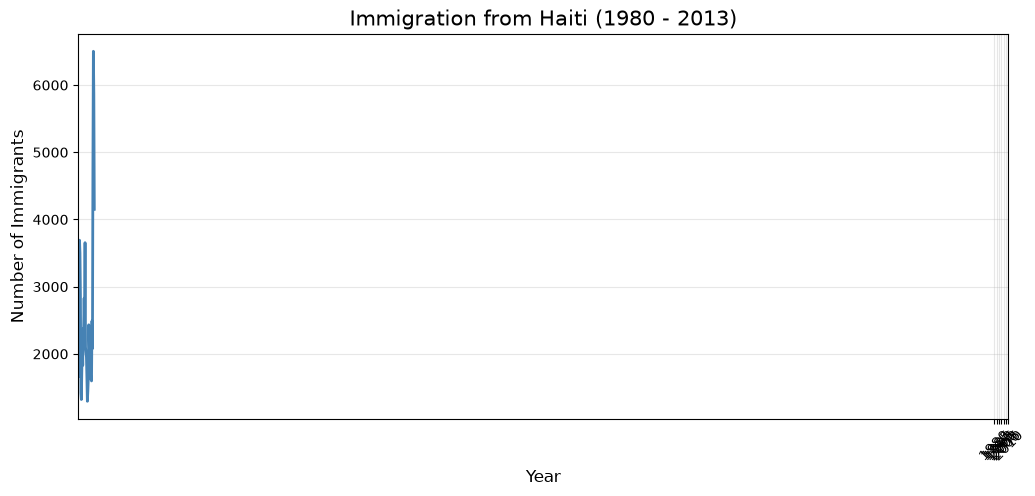

In [3]:
haiti = df_can.loc["Haiti", years]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(haiti.index, haiti.values, color="steelblue", linewidth=2)

ax.set_title("Immigration from Haiti (1980 - 2013)", fontsize=15)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of Immigrants", fontsize=12)

# show every 5th year on the x-axis instead of all 34 labels
ax.set_xticks(range(1980, 2015, 5))
ax.set_xticklabels(range(1980, 2015, 5), rotation=45, fontsize=10)

ax.grid(True, alpha=0.3)

plt.show()

**What changed compared with `haiti.plot()`.** `ax.plot()` is given the year values
explicitly instead of relying on the Series index, and the ticks are chosen by hand
(`set_xticks` + `set_xticklabels`), so the x-axis is legible even with 34 points.

### 2.1 The same plot, fully customised

* `marker='o'` + `markersize` — show where the actual data points are;
* `linestyle='--'` and `color` — visual differentiation;
* `ax.legend()` — a legend needs a `label=` on the plot call;
* `ax.annotate()` — the same annotation idea as `plt.text()`, with an arrow in this case.

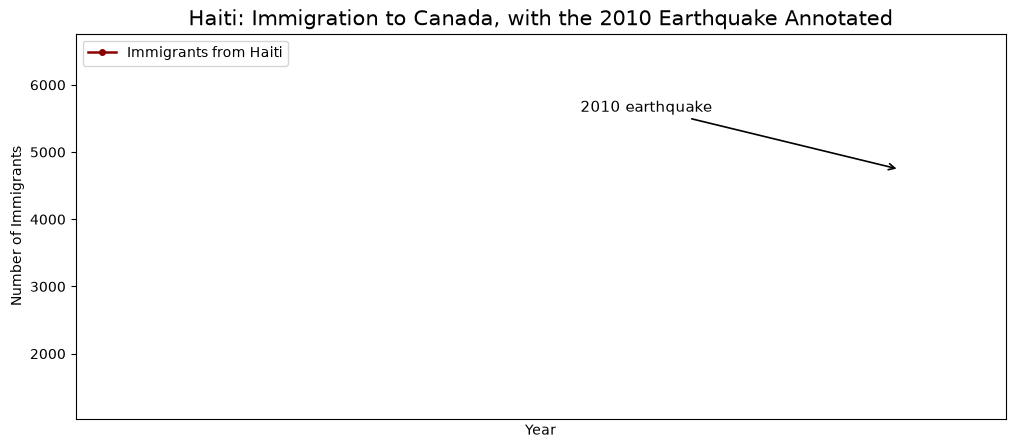

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(haiti.index, haiti.values,
        color="darkred", linewidth=1.8, linestyle="-",
        marker="o", markersize=4, label="Immigrants from Haiti")

ax.set_title("Haiti: Immigration to Canada, with the 2010 Earthquake Annotated", fontsize=15)
ax.set_xlabel("Year")
ax.set_ylabel("Number of Immigrants")

ax.annotate("2010 earthquake",
            xy=(2010, 4744), xytext=(1998, 5600),
            arrowprops=dict(facecolor="black", arrowstyle="->", lw=1.2),
            fontsize=11)

ax.legend(loc="upper left")
ax.set_xlim(1979, 2014)

plt.show()

**Reading the chart.** With the markers you can see that 2011 — not 2010 — is the peak
(6,503 arrivals): the *decision* to accept refugees was taken in 2010, the *arrivals* land in
2011. Annotating the cause and pointing at the effect is the difference between a chart and
a story.

---
## Step 3 — Scatter plot with `ax.scatter()`

Scatter plots compare two numeric variables. Here: immigration from **Italy** (x) against
immigration from **Japan** (y), one point per year.

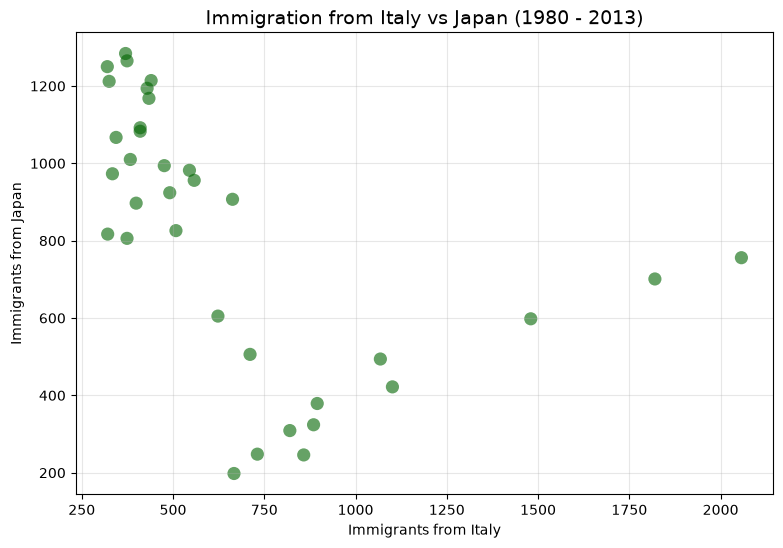

In [5]:
italy = df_can.loc["Italy", years]
japan = df_can.loc["Japan", years]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(italy.values, japan.values,
           c="darkgreen", alpha=0.6, marker="o", s=90, edgecolors="none")

ax.set_title("Immigration from Italy vs Japan (1980 - 2013)", fontsize=14)
ax.set_xlabel("Immigrants from Italy")
ax.set_ylabel("Immigrants from Japan")
ax.grid(True, alpha=0.3)

plt.show()

**Reading the chart.** The cloud is broad, not a tight diagonal, so the two flows are only
weakly related: years with many Italian arrivals are not systematically years with many
Japanese arrivals. `alpha=0.6` matters here — where points overlap they darken, which shows
where most years actually sit.

---
## Step 4 — Bar plot with `ax.bar()`

A bar chart compares a numeric value across categories. We rank the countries by `Total`
and draw the top five.

In [6]:
df_can.sort_values(by="Total", ascending=False, axis=0, inplace=True)

top5 = df_can["Total"].head(5)
print(top5)

Country
India                                                   691904
China                                                   659962
United Kingdom of Great Britain and Northern Ireland    551500
Philippines                                             511391
Pakistan                                                241600
Name: Total, dtype: int64


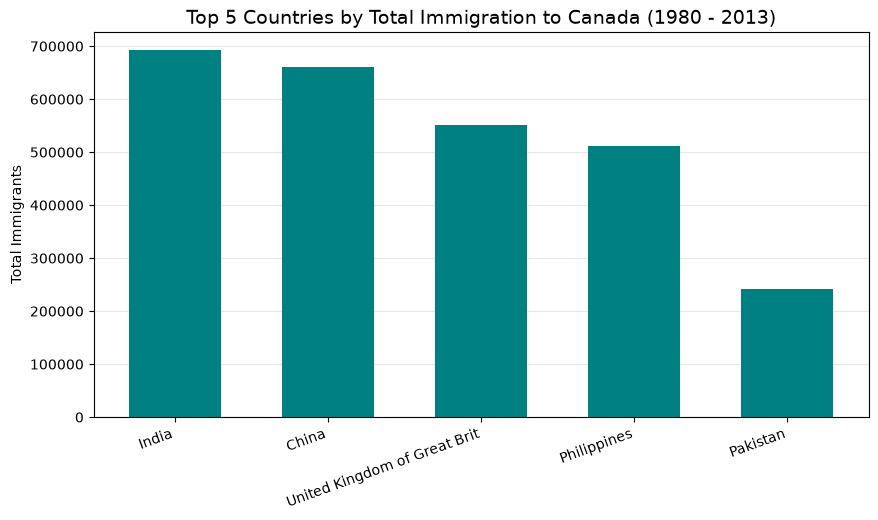

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(top5.index, top5.values, color="teal", width=0.6)

ax.set_title("Top 5 Countries by Total Immigration to Canada (1980 - 2013)", fontsize=14)
ax.set_ylabel("Total Immigrants")

# the third label is 45 characters long - shorten it and rotate the rest
short_labels = [str(c)[:28] for c in top5.index]
ax.set_xticks(range(len(top5)))
ax.set_xticklabels(short_labels, rotation=20, ha="right", fontsize=10)

ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.show()

### 4.1 The other end of the ranking — the five smallest sources

> **Question.** Create a bar plot of the 5 countries that contributed the **least** to
> immigration to Canada from 1980 to 2013.

In [8]:
bottom5 = df_can["Total"].tail(5)      # the frame is already sorted by Total
print(bottom5)

Country
San Marino          5
New Caledonia       5
Marshall Islands    2
Western Sahara      2
Palau               1
Name: Total, dtype: int64


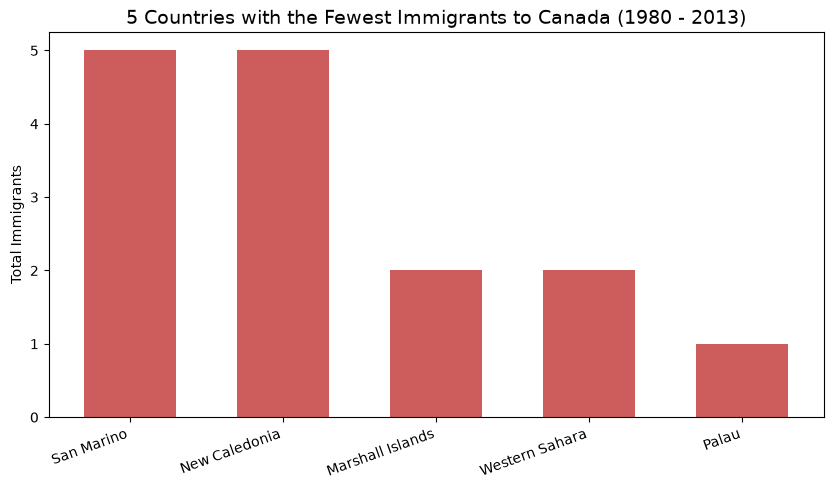

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(bottom5.index, bottom5.values, color="indianred", width=0.6)

ax.set_title("5 Countries with the Fewest Immigrants to Canada (1980 - 2013)", fontsize=14)
ax.set_ylabel("Total Immigrants")
ax.set_xticks(range(len(bottom5)))
ax.set_xticklabels(bottom5.index, rotation=20, ha="right", fontsize=10)

plt.show()

---
## Step 5 — Histogram with `ax.hist()`

A histogram shows the **frequency distribution** of one numeric variable: how many countries
fall into each bin of the 2013 immigration numbers. `ax.hist()` does the binning *and* the
counting, so we pass it the raw column, not a summary.

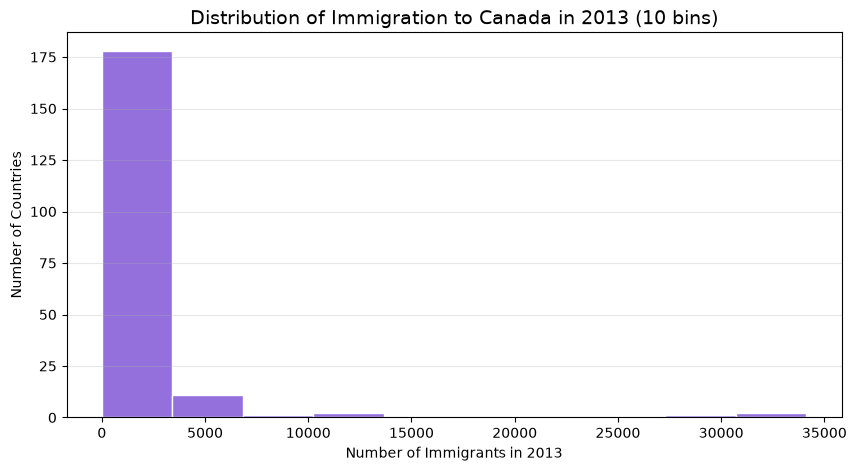

In [10]:
imm_2013 = df_can["2013"]

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(imm_2013.values, bins=10, color="mediumpurple", edgecolor="white")

ax.set_title("Distribution of Immigration to Canada in 2013 (10 bins)", fontsize=14)
ax.set_xlabel("Number of Immigrants in 2013")
ax.set_ylabel("Number of Countries")
ax.grid(True, axis="y", alpha=0.3)

plt.show()

### 5.1 Why the picture is one tall bar — the bin logic

`bins=10` cuts the whole range (0 → ~34,000) into ten equal-width bins about **3,400 wide**.
Almost every country sent fewer than 3,400 people, so almost every country lands in the first
bin: one tall bar, nine tiny ones. The bin *width* is the design decision, not the data.

In [11]:
print("min / max of 2013:", imm_2013.min(), "/", imm_2013.max())
print("bin width with 10 bins:", round((imm_2013.max() - imm_2013.min()) / 10, 1))
print("countries below 3,400:", int((imm_2013 < 3400).sum()), "of", len(imm_2013))

min / max of 2013: 0 / 34129
bin width with 10 bins: 3412.9
countries below 3,400: 178 of 195


### 5.2 More bins, and a log-free view of the tail

Raising `bins` to 15 shortens the bars (same total area, spread over more of them) and shows
that the distribution is heavily **right-skewed**: a long thin tail of a handful of countries
with tens of thousands of immigrants.

Bin edges: [0, 2275, 4551, 6826, 9101, 11376, 13652, 15927, 18202, 20477, 22753, 25028, 27303, 29578, 31854, 34129]
Counts   : [172, 14, 3, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 2]


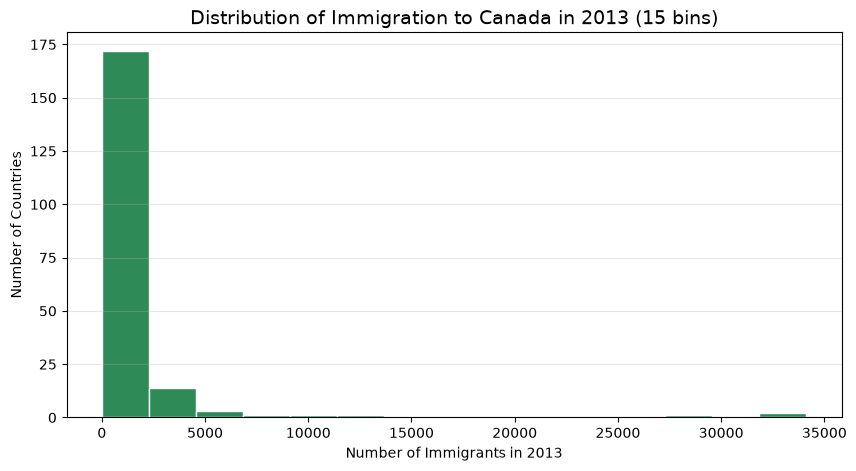

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, patches = ax.hist(imm_2013.values, bins=15,
                                     color="seagreen", edgecolor="white")

ax.set_title("Distribution of Immigration to Canada in 2013 (15 bins)", fontsize=14)
ax.set_xlabel("Number of Immigrants in 2013")
ax.set_ylabel("Number of Countries")
ax.grid(True, axis="y", alpha=0.3)

print("Bin edges:", np.round(bin_edges, 0).astype(int).tolist())
print("Counts   :", counts.astype(int).tolist())
plt.show()

### 5.3 Two distributions on one axes

Drawing two histograms on the same axes with `alpha` makes the comparison possible: the
distribution for China and India over 2000–2013.

> **Question.** What is the immigration distribution for China and India for the years
> 2000 to 2013?

In [13]:
df_CI = df_can.loc[["China", "India"], years[20:]].transpose()   # years[20:] = 2000..2013
print("Years covered:", df_CI.index[0], "-", df_CI.index[-1], "| shape", df_CI.shape)
df_CI.head(3)

Years covered: 2000 - 2013 | shape (14, 2)


Country,China,India
2000,35529,28572
2001,36434,31223
2002,31961,31889


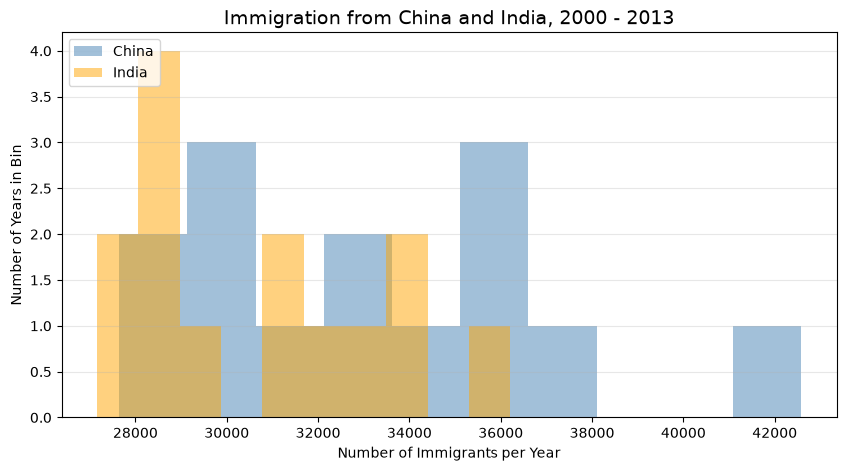

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(df_CI["China"].values, bins=10, alpha=0.5, label="China", color="steelblue")
ax.hist(df_CI["India"].values, bins=10, alpha=0.5, label="India", color="orange")

ax.set_title("Immigration from China and India, 2000 - 2013", fontsize=14)
ax.set_xlabel("Number of Immigrants per Year")
ax.set_ylabel("Number of Years in Bin")
ax.legend(loc="upper left")
ax.grid(True, axis="y", alpha=0.3)

plt.show()

**Reading the chart.** Both distributions sit between roughly 25,000 and 35,000 arrivals —
i.e. the two flows have converged in the 2000s, after diverging in the 1990s. With only 14
observations per country the histogram is coarse, which is exactly the limitation of a
histogram on small samples: a box plot (Module 02 Lab 02) or a line plot (Module 01 Lab 02)
would say the same thing more precisely.

---
## Step 6 — Pie chart with `ax.pie()`

The share of total immigration held by each continent. `ax.pie()` needs **one number per
slice**, so the frame is aggregated with `groupby()` first.

In [15]:
df_continents = df_can.groupby("Continent").sum(numeric_only=True)
print(df_continents["Total"])

Continent
Africa                              618948
Asia                               3317794
Europe                             1410947
Latin America and the Caribbean     765148
Northern America                    241142
Oceania                              55174
Name: Total, dtype: int64


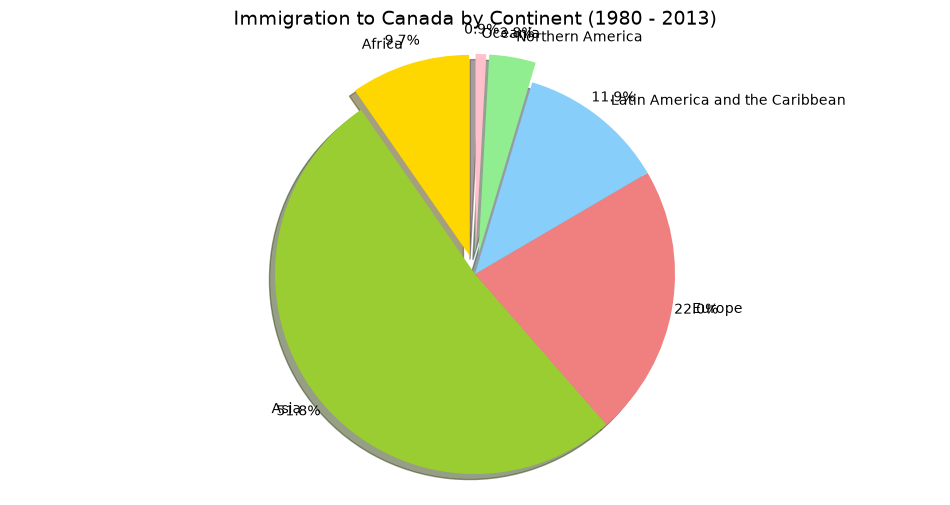

In [16]:
colors_list = ["gold", "yellowgreen", "lightcoral", "lightskyblue", "lightgreen", "pink"]
explode_list = [0.1, 0, 0, 0, 0.1, 0.1]

fig, ax = plt.subplots(figsize=(12, 6))

ax.pie(df_continents["Total"].values,
       labels=df_continents.index,
       autopct="%1.1f%%",
       pctdistance=1.12,
       colors=colors_list,
       startangle=90,
       explode=explode_list,
       shadow=True)

ax.set_title("Immigration to Canada by Continent (1980 - 2013)", fontsize=14)
ax.axis("equal")        # without this the pie is an ellipse

plt.show()

---
## Step 7 — Several charts on one figure

### 7.1 One row, two columns

`plt.subplots(1, 2)` returns a *list* of axes, one per position. Each is then used exactly
like the single `ax` above.

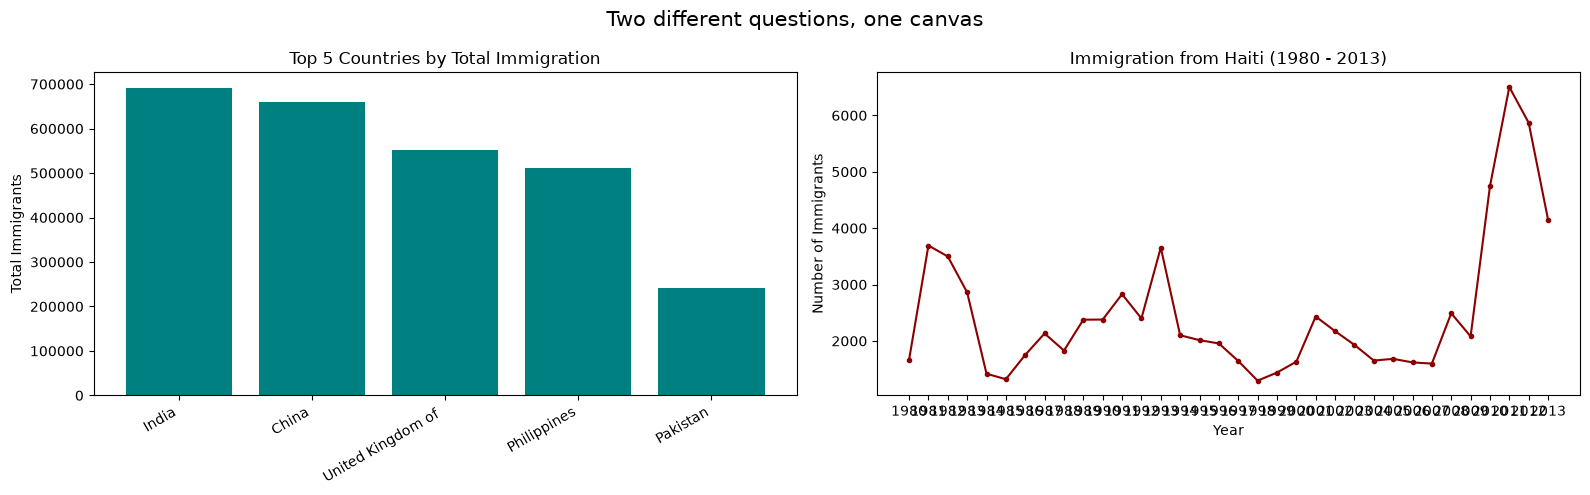

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# left: the top-5 bar chart
axs[0].bar(top5.index, top5.values, color="teal")
axs[0].set_title("Top 5 Countries by Total Immigration")
axs[0].set_ylabel("Total Immigrants")
axs[0].set_xticks(range(len(top5)))
axs[0].set_xticklabels([str(c)[:18] for c in top5.index], rotation=30, ha="right")

# right: the Haiti line chart
axs[1].plot(haiti.index, haiti.values, color="darkred", marker="o", markersize=3)
axs[1].set_title("Immigration from Haiti (1980 - 2013)")
axs[1].set_xlabel("Year")
axs[1].set_ylabel("Number of Immigrants")

fig.suptitle("Two different questions, one canvas", fontsize=15)
plt.tight_layout()
plt.show()

### 7.2 Two rows, two columns

The same call with `2, 2` gives a 2×2 grid; `axs` is now a 2-D array, indexed `axs[row, col]`.
This is how a dashboard-style "small multiples" page is built in pure Matplotlib.

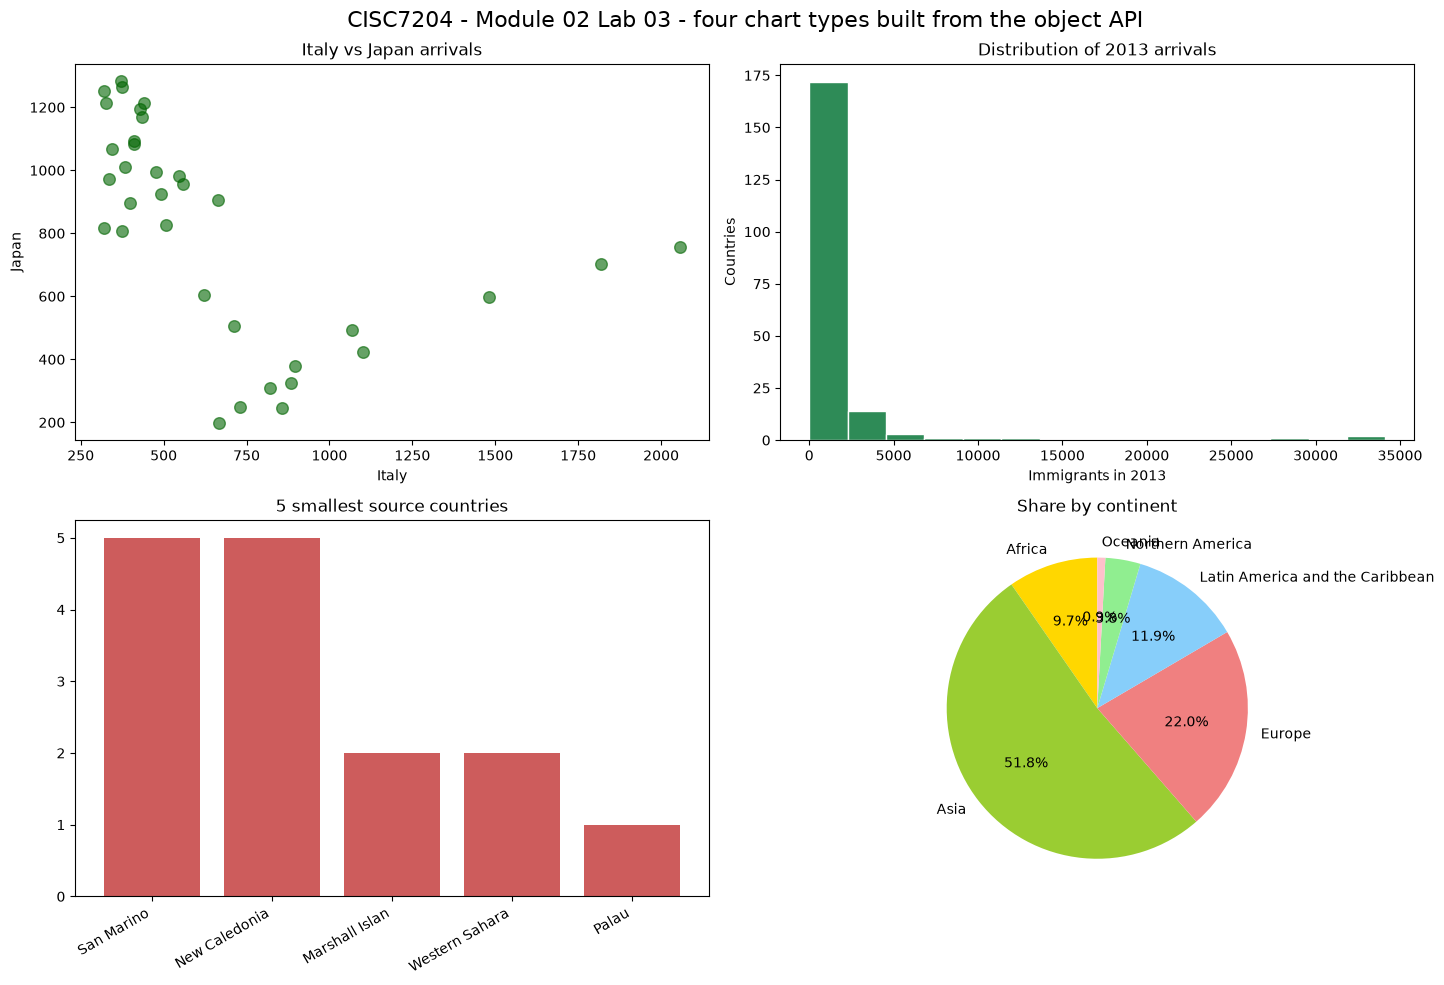

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

# (0,0) scatter: Italy vs Japan
axs[0, 0].scatter(italy.values, japan.values, c="darkgreen", alpha=0.6, s=70)
axs[0, 0].set_title("Italy vs Japan arrivals")
axs[0, 0].set_xlabel("Italy")
axs[0, 0].set_ylabel("Japan")

# (0,1) histogram: distribution of 2013
axs[0, 1].hist(imm_2013.values, bins=15, color="seagreen", edgecolor="white")
axs[0, 1].set_title("Distribution of 2013 arrivals")
axs[0, 1].set_xlabel("Immigrants in 2013")
axs[0, 1].set_ylabel("Countries")

# (1,0) bar: bottom 5
axs[1, 0].bar(bottom5.index, bottom5.values, color="indianred")
axs[1, 0].set_title("5 smallest source countries")
axs[1, 0].set_xticks(range(len(bottom5)))
axs[1, 0].set_xticklabels([str(c)[:14] for c in bottom5.index], rotation=30, ha="right")

# (1,1) pie: continents
axs[1, 1].pie(df_continents["Total"].values, labels=df_continents.index,
              autopct="%1.1f%%", colors=colors_list, startangle=90)
axs[1, 1].set_title("Share by continent")

fig.suptitle("CISC7204 - Module 02 Lab 03 - four chart types built from the object API",
             fontsize=16)
plt.tight_layout()
plt.show()

---
## What I learned (evidence of learning)

| Requirement of the lab | Where it is shown |
|---|---|
| `fig, ax = plt.subplots()` and draw on `ax` | Steps 2, 3, 4 |
| Titles, axis labels, ticks, rotation, grid, legend, limits | Step 2.1 |
| Line / scatter / bar / histogram / pie, all from the object API | Steps 2–6 |
| Annotate on the canvas with an arrow (`ax.annotate`) | Step 2.1 |
| Explain and change histogram bins | Steps 5.1–5.2 |
| Two distributions on one axes with `alpha` | Step 5.3 |
| 1×2 and 2×2 layouts on one figure | Steps 7.1–7.2 |

**The idea to keep.** pandas' `.plot()` is a shortcut into Matplotlib; the object API is the
real thing. Once the figure and the axes are separate objects, one figure can hold any number
of charts, and *every* pixel of every chart — tick, label, limit, colour — is under control.